In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['pdf.fonttype'] = 42

plt.rcParams['ps.fonttype'] = 42

plt.rcParams['font.family'] = 'sans-serif'

plt.rcParams['font.sans-serif'] = 'Arial'
 

# ------------------------------------------------------
# FUNCTIONS
# ------------------------------------------------------

def count_mutation_types(df):
    """
    Count how many H / R / A appear in each column (excluding 'Site').
    Returns total counts for the whole file.
    """
    counts = {"H": 0, "R": 0, "A": 0}

    mutation_columns = [c for c in df.columns if c != "Site"]

    for col in mutation_columns:
        col_values = df[col].values

        counts["H"] += np.sum(col_values == "H")
        counts["R"] += np.sum(col_values == "R")
        counts["A"] += np.sum(col_values == "A")

    return counts


def compute_percentages(counts):
    """Return H, R, A percentages."""
    total = sum(counts.values())
    return {
        "H_pct": (counts["H"] / total) * 100,
        "R_pct": (counts["R"] / total) * 100,
        "A_pct": (counts["A"] / total) * 100,
    }


def plot_mutation_burden(percentages, x_label, output_path):
    """
    Plot a stacked bar chart of H/R/A percentages.
    """
    H = percentages["H_pct"]
    R = percentages["R_pct"]
    A = percentages["A_pct"]

    fig, ax = plt.subplots(figsize=(1.5, 5))

    x = [x_label]

    ax.bar(x, H, color="#D55E00", edgecolor="black", width=0.3)
    ax.bar(x, R, bottom=H, color="#009E73", edgecolor="black", width=0.3)
    ax.bar(x, A, bottom=H + R, color="#0072B2", edgecolor="black", width=0.3)

    

    ax.tick_params(axis='both', labelsize=14)
    ax.set_ylabel("Burden (%)", fontsize=16)
    ax.tick_params(axis='x', labelsize=16)   # ← Increase x-label font size


    ax.set_ylim(0, 100)
    ax.legend(["Heterozygous (RA)", "Homozygous reference (RR)", "Homozygous alternate (AA)"],
              loc="center left",
              bbox_to_anchor=(1, 0.1),
              fontsize=16)


    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close()


# ------------------------------------------------------
# MAIN SCRIPT
# ------------------------------------------------------

files_to_process = [
    ("../genotypes_no_PON.txt", "After\nvariant\nfiltering"),
    ("../genotypes_bef_pon.txt", "Before\nvariant\nfiltering"),
]



summary_rows = []

for file_path, x_label in files_to_process:

    df = pd.read_csv(file_path, sep="\t")
    counts = count_mutation_types(df)
    percentages = compute_percentages(counts)

    # Add to summary table
    summary_rows.append({
        "File": x_label,
        "H_total": counts["H"],
        "R_total": counts["R"],
        "A_total": counts["A"],
        "H_pct": percentages["H_pct"],
        "R_pct": percentages["R_pct"],
        "A_pct": percentages["A_pct"],
    })

    # Save plot
    pdf_path = f"mutation_burden_{x_label}.pdf"
    plot_mutation_burden(percentages, x_label, pdf_path)

# Export the summary table
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv("mutation_burden_summary.csv", index=False)

print("Processing complete!")
print(summary_df)


Processing complete!
                         File  H_total  R_total  A_total      H_pct  \
0   After\nvariant\nfiltering   191911    95177    29392  60.639219   
1  Before\nvariant\nfiltering   306839   110660   116389  57.472541   

       R_pct      A_pct  
0  30.073622   9.287159  
1  20.727194  21.800265  


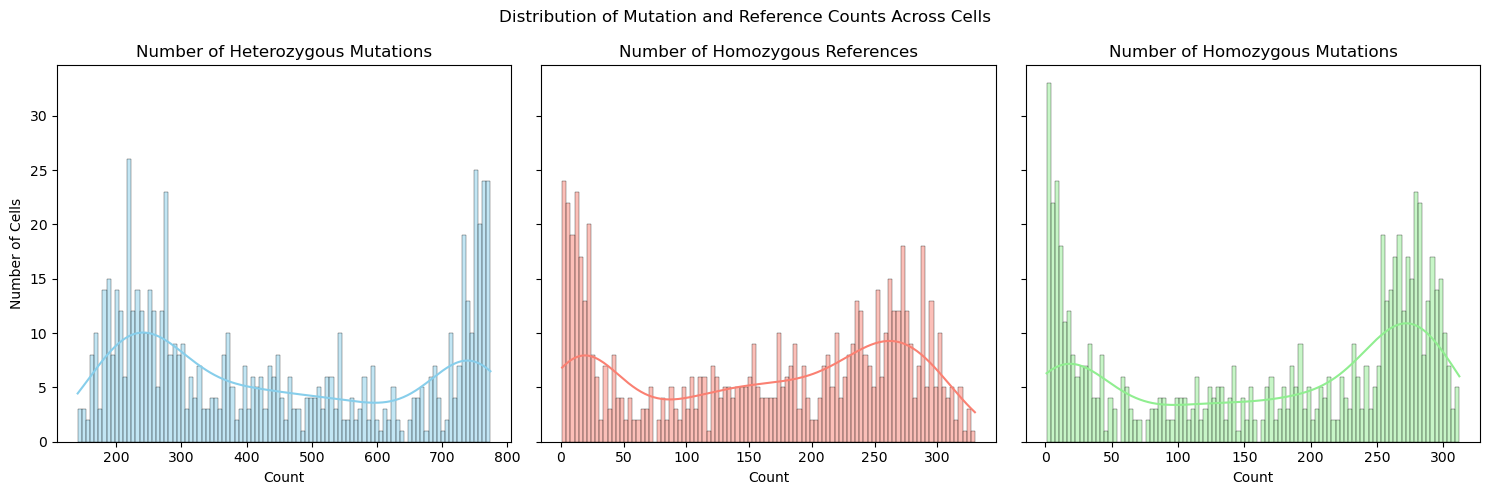

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sample data
data = dict_mutations_or_ref

# Extract values for each attribute
num_of_H = [values[0] for values in data.values()]
num_of_R = [values[1] for values in data.values()]
num_of_A = [values[2] for values in data.values()]

# Set up the plot
fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
fig.suptitle("Distribution of Mutation and Reference Counts Across Cells")

# Plot histograms
sns.histplot(num_of_H, bins=100, kde=True, ax=axs[0], color='skyblue')
axs[0].set_title("Number of Heterozygous Mutations")
axs[0].set_xlabel("Count")
axs[0].set_ylabel("Number of Cells")

sns.histplot(num_of_R, bins=100, kde=True, ax=axs[1], color='salmon')
axs[1].set_title("Number of Homozygous References")
axs[1].set_xlabel("Count")

sns.histplot(num_of_A, bins=100, kde=True, ax=axs[2], color='lightgreen')
axs[2].set_title("Number of Homozygous Mutations")
axs[2].set_xlabel("Count")

plt.tight_layout()
plt.show()
